##### Cell 1 — Import functions and prepare data

In [1]:

# ==========================================================
# IT3091 - Telco Customer Churn
# SVM Model Development
# Member: IT24101808
# Step 13.1 - Baseline SVM
# ==========================================================

import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from sklearn.svm import SVC

from src.data_preparation import (
    load_and_clean_data,
    separate_features_target
)
from src.validation import create_train_test_split
from src.imbalance import build_model_pipeline
from src.evaluation import evaluate_cv

# Load cleaned dataset
df = load_and_clean_data(project_root)

# Separate predictors and target
X, y = separate_features_target(df)

# Reuse shared 80/20 stratified split
X_train, X_test, y_train, y_test = (
    create_train_test_split(X, y)
)

print("SVM imports successful!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape[1])


SVM imports successful!
Training records: 5634
Testing records: 1409
Training features: 19


##### Cell 2 — Build baseline SVM pipeline

In [2]:

# Baseline SVM configuration
# Linear kernel, default C=1
# No engineered features or balancing

svm_baseline = build_model_pipeline(
    model=SVC(
        kernel="linear",
        C=1.0,
        class_weight=None,
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="none"
)

print("SVM baseline pipeline:")
print(list(svm_baseline.named_steps.keys()))


SVM baseline pipeline:
['features', 'preprocessor', 'model']


##### Cell 3 — Evaluate baseline SVM

In [3]:

# Stratified 5-fold cross-validation
# Training set only - no test set evaluation

svm_baseline_results = evaluate_cv(
    svm_baseline,
    X_train,
    y_train
)

display(svm_baseline_results)


,Metric,Mean,Std
0,F1,0.5857,0.0217
1,Recall,0.5344,0.0252
2,Precision,0.6487,0.0275
3,ROC_AUC,0.8338,0.0131
4,Accuracy,0.7994,0.0109


##### Cell 4 — Build the RBF SVM

In [4]:

# ==========================================================
# Step 13.2 - RBF SVM
# Member: IT24101808
# ==========================================================

svm_rbf = build_model_pipeline(
    model=SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None,
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="none"
)

print("RBF SVM pipeline:")
print(list(svm_rbf.named_steps.keys()))


RBF SVM pipeline:
['features', 'preprocessor', 'model']


##### Cell 5 — Evaluate RBF SVM

In [5]:

# Evaluate RBF SVM using the shared CV function

svm_rbf_results = evaluate_cv(
    svm_rbf,
    X_train,
    y_train
)

display(svm_rbf_results)


,Metric,Mean,Std
0,F1,0.5767,0.0139
1,Recall,0.5010,0.0184
2,Precision,0.6802,0.0189
3,ROC_AUC,0.7977,0.0176
4,Accuracy,0.8049,0.0060


##### Cell 6 — Compare both kernels and save the results

In [6]:

# ==========================================================
# Compare Linear vs RBF
# Save reproducible comparison table
# ==========================================================

import pandas as pd

linear_table = svm_baseline_results.copy()
linear_table["Kernel"] = "Linear"

rbf_table = svm_rbf_results.copy()
rbf_table["Kernel"] = "RBF"

kernel_comparison = pd.concat(
    [linear_table, rbf_table],
    ignore_index=True
)

kernel_comparison = kernel_comparison[
    ["Kernel", "Metric", "Mean", "Std"]
]

display(kernel_comparison)

# Save comparison table
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

kernel_comparison.to_csv(
    tables_dir / "svm_kernel_comparison.csv",
    index=False
)

print("Saved: results/tables/svm_kernel_comparison.csv")


,Kernel,Metric,Mean,Std
0,Linear,F1,0.5857,0.0217
1,Linear,Recall,0.5344,0.0252
2,Linear,Precision,0.6487,0.0275
3,Linear,ROC_AUC,0.8338,0.0131
4,Linear,Accuracy,0.7994,0.0109
5,RBF,F1,0.5767,0.0139
6,RBF,Recall,0.5010,0.0184
7,RBF,Precision,0.6802,0.0189
8,RBF,ROC_AUC,0.7977,0.0176
9,RBF,Accuracy,0.8049,0.0060


Saved: results/tables/svm_kernel_comparison.csv


##### Cell 7 — Save the kernel comparison graph

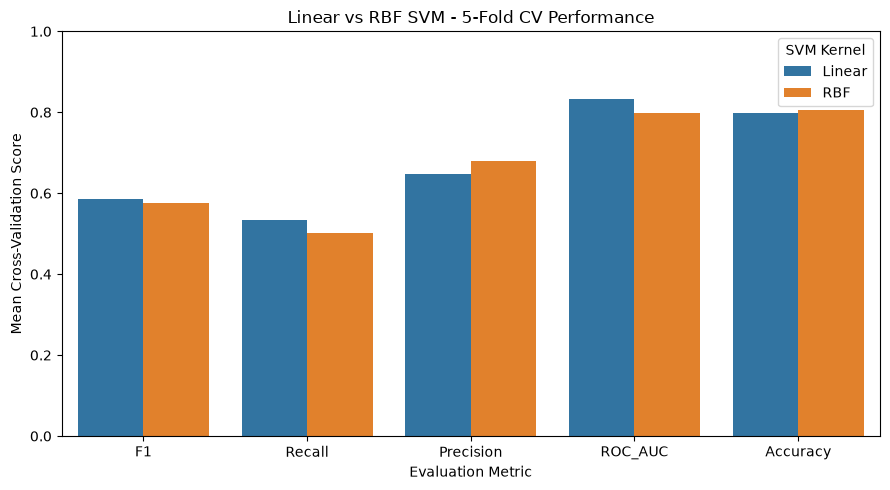

Saved: results/figures/svm/svm_kernel_comparison.png


In [7]:

# ==========================================================
# Visual comparison of SVM kernels
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns

plot_data = kernel_comparison.copy()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Mean",
    hue="Kernel"
)

plt.title("Linear vs RBF SVM - 5-Fold CV Performance")
plt.ylabel("Mean Cross-Validation Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="SVM Kernel")
plt.tight_layout()

figures_dir = project_root / "results" / "figures" / "svm"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "svm_kernel_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/figures/svm/svm_kernel_comparison.png")


##### Cell 8 — Hyperparameter tuning

In [8]:

# ==========================================================
# Step 13.3 - SVM Hyperparameter Tuning
# Member: IT24101808
# ==========================================================

from sklearn.model_selection import GridSearchCV
from src.validation import get_cross_validation

# Shared SVM pipeline
svm_tuning_pipeline = build_model_pipeline(
    model=SVC(random_state=42),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="none"
)

# Candidate parameter combinations
svm_param_grid = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1]
    }
]

svm_grid = GridSearchCV(
    estimator=svm_tuning_pipeline,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=get_cross_validation(),
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

svm_grid.fit(X_train, y_train)

print("Best parameters:")
print(svm_grid.best_params_)

print("\nBest CV F1-score:")
print(round(svm_grid.best_score_, 4))


Best parameters:
{'model__C': 1, 'model__kernel': 'linear'}

Best CV F1-score:
0.5857


##### Cell 9 — Save the tuning results

In [9]:

# ==========================================================
# Save all tuning results
# ==========================================================

import pandas as pd

svm_tuning_results = pd.DataFrame(
    svm_grid.cv_results_
)

columns = [
    "param_model__kernel",
    "param_model__C",
    "param_model__gamma",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "rank_test_score"
]

svm_tuning_table = svm_tuning_results[columns].copy()

svm_tuning_table = svm_tuning_table.sort_values(
    "rank_test_score"
)

display(svm_tuning_table)

output_path = (
    project_root
    / "results"
    / "tables"
    / "svm_hyperparameter_tuning.csv"
)

svm_tuning_table.to_csv(output_path, index=False)

print("Saved:", output_path)


,param_model__kernel,param_model__C,param_model__gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
1,linear,1.0,NaN,0.585700,0.021666,0.587435,1
2,linear,10.0,NaN,0.584166,0.021439,0.587076,2
0,linear,0.1,NaN,0.583935,0.022083,0.589233,3
6,rbf,1.0,scale,0.576711,0.013941,0.618266,4
8,rbf,1.0,0.1,0.575710,0.015441,0.629215,5
9,rbf,10.0,scale,0.568501,0.014350,0.733559,6
10,rbf,10.0,0.01,0.566335,0.015575,0.587203,7
7,rbf,1.0,0.01,0.563918,0.012894,0.572314,8
11,rbf,10.0,0.1,0.559299,0.025332,0.789073,9
3,rbf,0.1,scale,0.539514,0.015038,0.547749,10


Saved: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\tables\svm_hyperparameter_tuning.csv


##### Cell 10 — Build and evaluate imbalance strategies

In [10]:

# ==========================================================
# Step 13.4 - Class Imbalance Comparison
# ==========================================================

from sklearn.svm import SVC
import pandas as pd

imbalance_configs = [
    {
        "name": "No Balancing",
        "class_weight": None,
        "imbalance_strategy": "none"
    },
    {
        "name": "Class Weight",
        "class_weight": "balanced",
        "imbalance_strategy": "none"
    },
    {
        "name": "Random Oversampling",
        "class_weight": None,
        "imbalance_strategy": "random_oversampling"
    }
]

imbalance_results = []

for config in imbalance_configs:

    pipeline = build_model_pipeline(
        model=SVC(
            kernel="linear",
            C=1.0,
            class_weight=config["class_weight"],
            random_state=42
        ),
        scale_numeric=True,
        add_engineered_features=False,
        imbalance_strategy=config["imbalance_strategy"]
    )

    scores = evaluate_cv(
        pipeline,
        X_train,
        y_train
    )

    scores["Strategy"] = config["name"]
    imbalance_results.append(scores)

    print("Completed:", config["name"])

svm_imbalance_comparison = pd.concat(
    imbalance_results,
    ignore_index=True
)

svm_imbalance_comparison = svm_imbalance_comparison[
    ["Strategy", "Metric", "Mean", "Std"]
]

display(svm_imbalance_comparison)


Completed: No Balancing
Completed: Class Weight
Completed: Random Oversampling


,Strategy,Metric,Mean,Std
0,No Balancing,F1,0.5857,0.0217
1,No Balancing,Recall,0.5344,0.0252
2,No Balancing,Precision,0.6487,0.0275
3,No Balancing,ROC_AUC,0.8338,0.0131
4,No Balancing,Accuracy,0.7994,0.0109
5,Class Weight,F1,0.5983,0.0064
6,Class Weight,Recall,0.8355,0.0191
7,Class Weight,Precision,0.4661,0.0050
8,Class Weight,ROC_AUC,0.8302,0.0126
9,Class Weight,Accuracy,0.7023,0.0051


##### Cell 11 — Save the comparison table

In [11]:

# Save imbalance comparison results

output_path = (
    project_root
    / "results"
    / "tables"
    / "svm_imbalance_comparison.csv"
)

svm_imbalance_comparison.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)


Saved: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\tables\svm_imbalance_comparison.csv


##### Cell 12 — Save the comparison graph


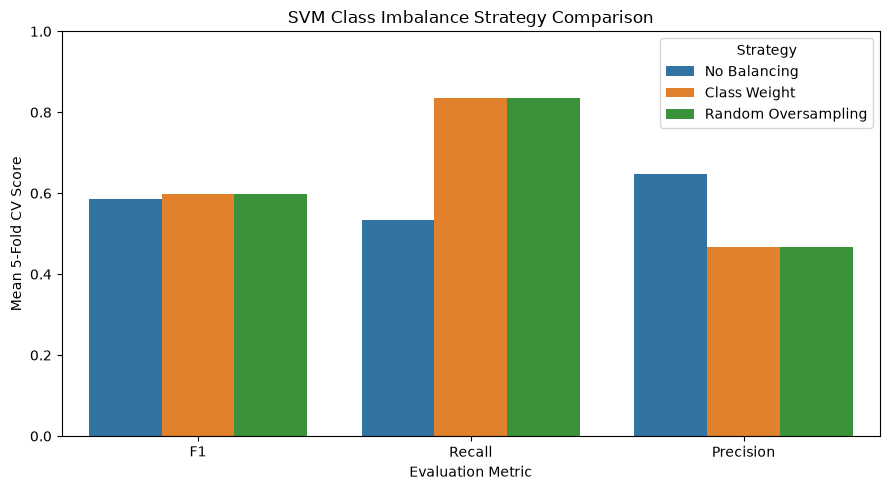

Saved: results/figures/svm/svm_imbalance_comparison.png


In [12]:

# Visualize F1, recall, and precision
# for each imbalance strategy

import matplotlib.pyplot as plt
import seaborn as sns

plot_data = svm_imbalance_comparison[
    svm_imbalance_comparison["Metric"].isin(
        ["F1", "Recall", "Precision"]
    )
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Mean",
    hue="Strategy"
)

plt.title("SVM Class Imbalance Strategy Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Mean 5-Fold CV Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    figures_dir / "svm_imbalance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/figures/svm/svm_imbalance_comparison.png")


##### Cell 13 — Evaluate feature engineering configurations

In [13]:

# ==========================================================
# Step 13.5 - Feature Engineering Comparison
# Member: IT24101808
# ==========================================================

from sklearn.svm import SVC
import pandas as pd

feature_configs = [
    {
        "name": "Original",
        "engineered": False,
        "class_weight": None
    },
    {
        "name": "Original + Balanced",
        "engineered": False,
        "class_weight": "balanced"
    },
    {
        "name": "Engineered",
        "engineered": True,
        "class_weight": None
    },
    {
        "name": "Engineered + Balanced",
        "engineered": True,
        "class_weight": "balanced"
    }
]

feature_results = []

for config in feature_configs:

    pipeline = build_model_pipeline(
        model=SVC(
            kernel="linear",
            C=1.0,
            class_weight=config["class_weight"],
            random_state=42
        ),
        scale_numeric=True,
        add_engineered_features=config["engineered"],
        imbalance_strategy="none"
    )

    scores = evaluate_cv(
        pipeline,
        X_train,
        y_train
    )

    scores["Configuration"] = config["name"]
    feature_results.append(scores)

    print("Completed:", config["name"])

svm_feature_comparison = pd.concat(
    feature_results,
    ignore_index=True
)

svm_feature_comparison = svm_feature_comparison[
    ["Configuration", "Metric", "Mean", "Std"]
]

display(svm_feature_comparison)


Completed: Original
Completed: Original + Balanced
Completed: Engineered
Completed: Engineered + Balanced


,Configuration,Metric,Mean,Std
0,Original,F1,0.5857,0.0217
1,Original,Recall,0.5344,0.0252
2,Original,Precision,0.6487,0.0275
3,Original,ROC_AUC,0.8338,0.0131
4,Original,Accuracy,0.7994,0.0109
5,Original + Balanced,F1,0.5983,0.0064
6,Original + Balanced,Recall,0.8355,0.0191
7,Original + Balanced,Precision,0.4661,0.0050
8,Original + Balanced,ROC_AUC,0.8302,0.0126
9,Original + Balanced,Accuracy,0.7023,0.0051


##### Cell 14 — Save the results table

In [14]:

# ==========================================================
# Save feature engineering comparison
# ==========================================================

output_path = (
    project_root
    / "results"
    / "tables"
    / "svm_feature_comparison.csv"
)

svm_feature_comparison.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)


Saved: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\tables\svm_feature_comparison.csv


##### Cell 15 — Save the comparison graph

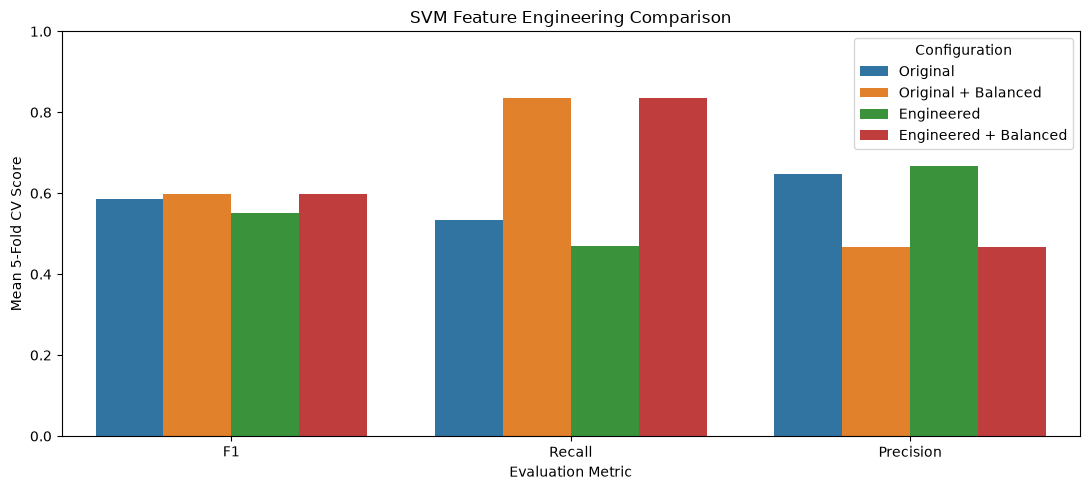

Saved: results/figures/svm/svm_feature_comparison.png


In [15]:

# ==========================================================
# Visualize feature engineering results
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns

plot_data = svm_feature_comparison[
    svm_feature_comparison["Metric"].isin(
        ["F1", "Recall", "Precision"]
    )
]

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Mean",
    hue="Configuration"
)

plt.title("SVM Feature Engineering Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Mean 5-Fold CV Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    figures_dir / "svm_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/figures/svm/svm_feature_comparison.png")


##### Tune C for the balanced SVM

In [16]:

# ==========================================================
# Step 13.6 - Tune Balanced Linear SVM
# ==========================================================

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from src.validation import get_cross_validation

balanced_svm_pipeline = build_model_pipeline(
    model=SVC(
        kernel="linear",
        class_weight="balanced",
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="none"
)

balanced_svm_grid = GridSearchCV(
    estimator=balanced_svm_pipeline,
    param_grid={
        "model__C": [0.01, 0.1, 1, 10]
    },
    scoring="f1",
    cv=get_cross_validation(),
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

balanced_svm_grid.fit(X_train, y_train)

print("Best C:", balanced_svm_grid.best_params_)
print("Best CV F1:", round(balanced_svm_grid.best_score_, 4))


Best C: {'model__C': 0.01}
Best CV F1: 0.6062


##### Cell 17 — Inspect overfitting and save tuning results

In [17]:

# ==========================================================
# Balanced SVM tuning results
# ==========================================================

balanced_tuning_table = pd.DataFrame(
    balanced_svm_grid.cv_results_
)[[
    "param_model__C",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

balanced_tuning_table = balanced_tuning_table.sort_values(
    "rank_test_score"
)

balanced_tuning_table["train_validation_gap"] = (
    balanced_tuning_table["mean_train_score"]
    - balanced_tuning_table["mean_test_score"]
)

display(balanced_tuning_table)

output_path = (
    project_root / "results" / "tables"
    / "svm_balanced_tuning.csv"
)

balanced_tuning_table.to_csv(output_path, index=False)

print("Saved:", output_path)


,param_model__C,mean_train_score,mean_test_score,std_test_score,rank_test_score,train_validation_gap
0,0.01,0.609784,0.606249,0.005318,1,0.003535
1,0.10,0.598321,0.598281,0.006373,2,0.000040
2,1.00,0.598321,0.598281,0.006373,2,0.000040
3,10.00,0.598321,0.598281,0.006373,2,0.000040


Saved: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\tables\svm_balanced_tuning.csv


##### Cell 18 — Evaluate the selected configuration using all five metrics

In [18]:

# ==========================================================
# Selected SVM - Cross-Validation Metrics
# ==========================================================

best_svm_pipeline = balanced_svm_grid.best_estimator_

# Important:
# best_estimator_ is already fitted on the full training set.
# evaluate_cv will refit clones within CV training folds.

best_svm_cv_results = evaluate_cv(
    best_svm_pipeline,
    X_train,
    y_train
)

display(best_svm_cv_results)

output_path = (
    project_root / "results" / "tables"
    / "svm_final_cv.csv"
)

best_svm_cv_results.to_csv(output_path, index=False)

print("Saved:", output_path)


,Metric,Mean,Std
0,F1,0.6062,0.0053
1,Recall,0.8261,0.0240
2,Precision,0.4791,0.0072
3,ROC_AUC,0.8415,0.0095
4,Accuracy,0.7153,0.0072


Saved: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\tables\svm_final_cv.csv


##### Cell 19 — Save the trained SVM model

In [19]:

# ==========================================================
# Save fitted SVM pipeline
# ==========================================================

import joblib

models_dir = project_root / "results" / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "svm.joblib"

joblib.dump(best_svm_pipeline, model_path)

print("Saved trained SVM:", model_path)
print("Selected C:", best_svm_pipeline.named_steps["model"].C)
print("Kernel:", best_svm_pipeline.named_steps["model"].kernel)
print("Class weight:", best_svm_pipeline.named_steps["model"].class_weight)


Saved trained SVM: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\models\svm.joblib
Selected C: 0.01
Kernel: linear
Class weight: balanced


##### 20 — Save the SVM model summary

In [20]:

# ==========================================================
# Stage 13.7 - Save SVM Summary for Group Comparison
# ==========================================================

import pandas as pd

final_svm = best_svm_pipeline.named_steps["model"]

metric_values = best_svm_cv_results.set_index("Metric")["Mean"]

svm_summary = pd.DataFrame([{
    "Model": "Support Vector Machine",
    "Kernel": final_svm.kernel,
    "C": final_svm.C,
    "Class_Weight": str(final_svm.class_weight),
    "Engineered_Features": False,
    "Imbalance_Strategy": "class_weight",
    "F1": metric_values["F1"],
    "Recall": metric_values["Recall"],
    "Precision": metric_values["Precision"],
    "ROC_AUC": metric_values["ROC_AUC"],
    "Accuracy": metric_values["Accuracy"]
}])

display(svm_summary)

summary_path = (
    project_root / "results" / "tables"
    / "svm_model_summary.csv"
)

svm_summary.to_csv(summary_path, index=False)

print("Saved:", summary_path)


,Model,Kernel,C,Class_Weight,Engineered_Features,Imbalance_Strategy,F1,Recall,Precision,ROC_AUC,Accuracy
0,Support Vector Machine,linear,0.01,balanced,False,class_weight,0.6062,0.8261,0.4791,0.8415,0.7153


Saved: c:\Users\USER\Desktop\IT3091_Telco_Churn--2\results\tables\svm_model_summary.csv


##### Cell 21-SVM cross-validated ROC curve

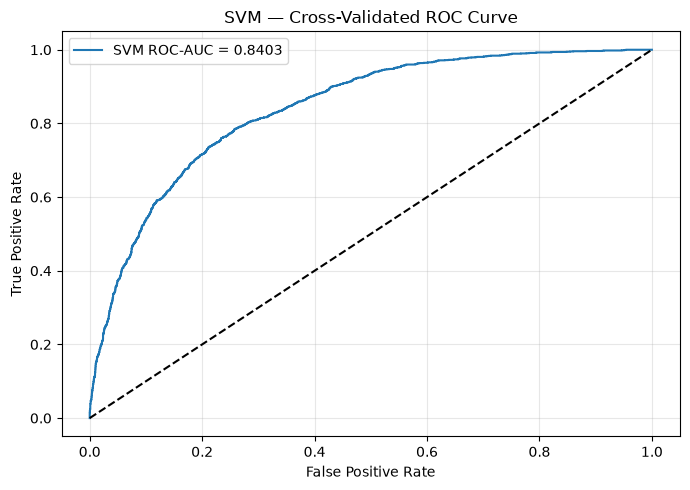

Saved SVM ROC curve.


In [21]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Out-of-fold SVM decision scores
svm_scores = cross_val_predict(
    best_svm_pipeline,
    X_train,
    y_train,
    cv=get_cross_validation(),
    method="decision_function"
)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_train, svm_scores)
auc = roc_auc_score(y_train, svm_scores)

# Plot
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"SVM ROC-AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM — Cross-Validated ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
svm_figures_dir = project_root / "results" / "figures" / "svm"
svm_figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    svm_figures_dir / "svm_cv_roc_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("Saved SVM ROC curve.")
